# Climate Forcing by Anthropogenic Aerosols: the Direct Sulfate Forcing Box Model

__R. J. Charlson__, Department of Atmospheric Sciences and Institute for Environmental Studies, University of Washington, Seattle, WA

__S. E. Schwartz__, Environmental Chemistry Division, Brookhaven National Laboratory, Upton, NY

__J. M. Hales__, Atmospheric Sciences Department, Pacific Northwest Laboratory, Richland, WA

__R. D. Cess__, Institute for Terrestrial and Planetary Atmospheres, State University of New York, Stony Brook, NY

__J. A. Coakley, Jr.__, Department of Atmospheric Sciences, Oregon State University, Corvallis, OR

__J. E. Hansen__, Goddard Institute for Space Studies, National Aeronautics and Space Administration, New York, NY

__D. J. Hofmann__, Climate Monitoring and Diagnostics Laboratory, National Oceanic and Atmospheric Administration, Boulder, CO

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes a few seconds.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import sulfur_model as sm

SEED = 1992                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
labels = [r'$Q$', r'$Y$', r'$L$', r'$\Psi_e$', r'$\bar\beta$', r'$f_{\Psi}$', r'$T^2$',
          r'$1-A_c$', r'$(1-R_s)^2$']

### Summary

Charlson et al. [[1]](https://doi.org/10.1126/science.255.5043.423) estimate the global-mean direct shortwave forcing of anthropogenic sulfate aerosol with a box model that is a product of nine uncertain factors (sulfur source, sulfate yield and lifetime, scattering efficiency, hygroscopic growth, upscatter fraction, transmittance, cloud-free fraction and surface coalbedo), and get $-1.3$ W m$^{-2}$ from their nominal values. We give the nine factors the independent lognormal distributions of the uncertainty-quantification benchmark version of this model (Penner et al. [[2]](https://doi.org/10.1175/1520-0477(1994)075<0375:QAMUOC>2.0.CO;2), as tabulated by UQTestFuns [[3]](https://doi.org/10.21105/joss.05671)) and compute the active subspace of the forcing with respect to the logarithms of the inputs, from 1000 samples with exact gradients. In log coordinates the forcing is an exponential of a linear function, so the active subspace is exactly one-dimensional, with weights proportional to the log-scale standard deviations of the inputs; in the original (physical) coordinates the same direction appears, but with a smaller eigenvalue gap and a worse one-dimensional fit.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

Charlson et al. [[1]](https://doi.org/10.1126/science.255.5043.423) (p. 426, Eqs. 1–5) write the areal-mean direct forcing as

$$
\Delta F_R = -\tfrac12 F_T\, T^2 (1 - A_c)(1-R_s)^2\,\bar\beta\,\delta_{\mathrm{SO_4^{2-}}},\qquad
\delta_{\mathrm{SO_4^{2-}}} = \alpha_{\mathrm{SO_4^{2-}}}\, f(\mathrm{RH})\, B_{\mathrm{SO_4^{2-}}},\qquad
B_{\mathrm{SO_4^{2-}}} = \frac{Q_{\mathrm{SO_2}}\,Y_{\mathrm{SO_4^{2-}}}\,\tau_{\mathrm{SO_4^{2-}}}}{A},
$$

where $F_T$ is the solar constant, $T$ the transmittance of the atmosphere above the aerosol layer, $A_c$ the cloud fraction, $R_s$ the surface albedo, $\bar\beta$ the upscatter fraction, $\delta$ the aerosol optical depth, $\alpha$ the mass scattering efficiency, $f(\mathrm{RH})$ the hygroscopic growth factor, $B$ the sulfate column burden, $Q$ the anthropogenic SO$_2$ source, $Y$ the sulfate yield, $\tau$ the sulfate lifetime and $A$ the area of the earth. Their Table 1 (p. 426) gives nominal values and relative uncertainties, but no distributions.

The benchmark version, which we use (UQTestFuns [[3]](https://doi.org/10.21105/joss.05671), after Penner et al. [[2]](https://doi.org/10.1175/1520-0477(1994)075<0375:QAMUOC>2.0.CO;2) and Tatang et al. [[4]](https://doi.org/10.1029/97JD01654)), takes $T^2$ and $(1-R_s)^2$ as inputs, writes $\Psi_e$ for $\alpha$ (per gram of sulfate), $f_\Psi$ for $f(\mathrm{RH})$ and $L$ (days) for $\tau$, and converts units explicitly:

$$
\Delta F_R(\mathbf x) = -\tfrac12 S_0\,(1-A_c)\,T^2\,(1-R_s)^2\,\bar\beta\,\Psi_e\,f_\Psi\;\frac{3\cdot 10^{12}\,Q\,Y\,L}{365\,A},
$$

with $S_0 = 1361$ W m$^{-2}$, $A = 5.1\times 10^{14}$ m$^2$, $Q$ in Tg S yr$^{-1}$, 3 the mass ratio of sulfate to sulfur and $365$ days per year. (UQTestFuns notes that Tatang et al.'s Eq. 12 squares $S_0$ and omits the factors $10^{12}$ and 365; Charlson et al. use $F_T = 1370$ W m$^{-2}$ and $A = 5\times10^{14}$ m$^2$.)

**Inputs and the transform.** The nine inputs are independent and lognormal, $\ln x_i \sim N(\mu_i, \sigma_i^2)$. Their medians $e^{\mu_i}$ match Charlson's nominal values except for $Q$ (71 vs 90 Tg S yr$^{-1}$), $Y$ (0.5 vs 0.4), $L$ (5.5 vs 7.3 days), $\bar\beta$ (0.30 vs 0.29) and $1-A_c$ (0.39 vs 0.4), and their $\sigma_i$ equal $\ln(1+u_i)$ with $u_i$ Charlson's relative uncertainty (doubled for the squared factors), except $\bar\beta$ ($\ln 1.3$ rather than $\ln 1.25$). The library's input spaces are uniform or Gaussian, so we work in the log inputs $\mathbf z = \ln\mathbf x$, which are exactly Gaussian, $\mathbf z\sim N(\boldsymbol\mu, \mathrm{diag}(\boldsymbol\sigma^2))$, and normalized by $x^{\mathrm{norm}}_i = (z_i-\mu_i)/\sigma_i$. The gradient we need is $\partial\Delta F_R/\partial z_i = x_i\,\partial \Delta F_R/\partial x_i$; because every input enters with power 1, it equals $\Delta F_R$ in every component, exactly.

**Quantity of interest.** $\Delta F_R$ in W m$^{-2}$ (negative: a cooling). We also look at $\ln(-\Delta F_R) = \ln(-K) + \sum_i z_i$, which is linear in $\mathbf z$.

The table below is built from `sulfur_model.py`.

In [2]:
med = np.exp(sm.MU)
print(f"{'input':16s} {'units':8s} {'mu':>9s} {'sigma':>9s} {'median':>8s} {'Charlson':>8s} {'u (T1)':>6s}  description")
for j, n in enumerate(sm.NAMES):
    print(f'{n:16s} {sm.UNITS[j] or "-":8s} {sm.MU[j]:9.5f} {sm.SIGMA[j]:9.6f} {med[j]:8.4g} '
          f'{sm.NOMINAL_CHARLSON[j]:8.4g} {sm.REL_UNC_CHARLSON[j]:6.0%}  {sm.DESCRIPTIONS[j]}')
mean, var = sm.moments()
print(f'\nconstants: S0 = {sm.S0:g} W/m^2, A = {sm.AREA:.2e} m^2; K = {sm.constant():.5e} W/m^2')
print(f'exact mean and variance of dF_R: {mean:.4f} W/m^2, {var:.4f} (W/m^2)^2 '
      f'(UQTestFuns, analytic: -1.2741, 1.7089)')
print(f'dF_R at the medians: {sm.forcing(med):.4f} W/m^2; at Charlson\'s nominal values with his '
      f'F_T = 1370 W/m^2 and A = 5e14 m^2: {sm.forcing(sm.NOMINAL_CHARLSON, sm.S0_CHARLSON, sm.AREA_CHARLSON):.4f} W/m^2 '
      f'(Table 1: -1.3)')

input            units           mu     sigma   median Charlson u (T1)  description
Q                Tg S/yr    4.26268  0.139762       71       90    15%  source strength of anthropogenic SO2
Y                -         -0.69315  0.405465      0.5      0.4    50%  fraction of emitted SO2 that reacts to form sulfate aerosol
L                days       1.70475  0.405465      5.5      7.3    50%  atmospheric lifetime of sulfate
Psi_e            m^2/g      1.60944  0.336472        5        5    40%  mass scattering efficiency of sulfate (alpha in Charlson et al.)
beta             -         -1.20397  0.262364      0.3     0.29    25%  fraction of scattered light scattered upward (beta bar)
f_Psi            -          0.53063  0.182322      1.7      1.7    20%  relative increase in scattering from hygroscopic growth (f(RH))
T2               -         -0.54473  0.336472     0.58   0.5776    20%  square of the transmittance T of the atmosphere above the aerosol layer
one_minus_Ac     -        

### Load data

`generate_data.py` drew $M = 1000$ samples of the inputs (seed 1992) and wrote the physical inputs, $\Delta F_R$, and its exact gradient with respect to $\mathbf z = \ln\mathbf x$ (see `DATA.md`).

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')        # (M, 9) physical inputs
f = np.loadtxt('outputs.csv', delimiter=',')       # (M,) dF_R in W/m^2
G = np.loadtxt('gradients.csv', delimiter=',')     # (M, 9) d(dF_R)/d(ln x_i) in W/m^2
Z = np.log(X)                                      # log inputs, the coordinates of the analysis
print(f'inputs {X.shape}, outputs {f.shape}, gradients {G.shape}')

inputs (1000, 9), outputs (1000,), gradients (1000, 9)


We check the files against the model and the exact gradients against central finite differences in $\mathbf z$ (step $10^{-6}$), and compare the sample mean and variance with the exact ones.

In [4]:
h = 1e-6
G_fd = np.column_stack([(sm.forcing(np.exp(Z + h*e)) - sm.forcing(np.exp(Z - h*e))) / (2*h)
                        for e in np.eye(9)])
print(f'max |model - outputs.csv| / |dF_R| = {np.max(np.abs(sm.forcing(X) - f) / np.abs(f)):.1e}; '
      f'gradients.csv vs central differences: max relative error {np.max(np.linalg.norm(G_fd - G, axis=1) / np.linalg.norm(G, axis=1)):.1e}')
print(f'sample mean {f.mean():.4f} (exact {mean:.4f}), sample variance {f.var(ddof=1):.4f} (exact {var:.4f}); '
      f'2.5/50/97.5 percentiles {np.percentile(f, [2.5, 50, 97.5]).round(3).tolist()} W/m^2')

max |model - outputs.csv| / |dF_R| = 0.0e+00; gradients.csv vs central differences: max relative error 2.3e-10
sample mean -1.2586 (exact -1.2741), sample variance 1.4944 (exact 1.7090); 2.5/50/97.5 percentiles [-4.725, -0.864, -0.169] W/m^2


### Estimate the subspace

The model is closed-form, so we have exact gradients and use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates. The input space is `ac.Gaussian` with mean $\boldsymbol\mu$ and variances $\boldsymbol\sigma^2$ on the **log** inputs; we pass $\mathbf Z = \ln\mathbf X$ and the gradients with respect to $\mathbf z$, and the library maps both to normalized coordinates once (the normalized gradient is $\sigma_i\,\partial\Delta F_R/\partial z_i$). We use 500 bootstrap replicates and the dimension rule of the library (largest eigenvalue gap).

Since $\nabla_{\mathbf z}\Delta F_R = \Delta F_R\,\mathbf 1$, the normalized gradient is $\Delta F_R\,\boldsymbol\sigma$, and $\mathbf C = \mathbb E[\Delta F_R^2]\,\boldsymbol\sigma\boldsymbol\sigma^T$ has rank one: $\lambda_1 = \mathbb E[\Delta F_R^2]\,\|\boldsymbol\sigma\|^2$, $\mathbf w_1 = \boldsymbol\sigma/\|\boldsymbol\sigma\|$, and $\lambda_2 = \dots = \lambda_9 = 0$.

In [5]:
space = ac.Gaussian(sm.MU, sm.SIGMA**2, names=[f'ln {n}' for n in sm.NAMES])
sub = ac.active_subspace(space=space, X=Z, f=f, grads=G, estimator='as', nboot=500, rng=SEED)
lam, w1 = sub.eigenvalues, sub.W[:, 0]
ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
lam1_exact = (var + mean**2) * np.sum(sm.SIGMA**2)
print('eigenvalues:', np.array2string(lam, precision=3))
print(f'n = {sub.n} (eigenvalue-gap rule picks {k_hat}); lambda_1 = {lam[0]:.4f}, exact '
      f'E[dF_R^2] |sigma|^2 = {lam1_exact:.4f}; sample estimate mean(f^2) |sigma|^2 = '
      f'{np.mean(f**2) * np.sum(sm.SIGMA**2):.4f}')
print(f'lambda_1/lambda_2 = {lam[0] / lam[1]:.1e}, lambda_2/lambda_3 = {lam[1] / lam[2]:.1f} '
      f'(lambda_2, ..., lambda_9 are rounding errors)')
print(f'|w1 - sigma/|sigma|| = {np.linalg.norm(w1 - sm.SIGMA / np.linalg.norm(sm.SIGMA)):.1e}')

eigenvalues: [2.213e+00 8.216e-33 1.741e-33 9.195e-34 4.927e-34 1.314e-34 3.701e-64
 2.263e-65 6.505e-66]
n = 1 (eigenvalue-gap rule picks 1); lambda_1 = 2.2129, exact E[dF_R^2] |sigma|^2 = 2.3965; sample estimate mean(f^2) |sigma|^2 = 2.2129
lambda_1/lambda_2 = 2.7e+32, lambda_2/lambda_3 = 4.7 (lambda_2, ..., lambda_9 are rounding errors)
|w1 - sigma/|sigma|| = 1.9e-16


### Results

**Eigenvalues.** The figure shows the eigenvalues with a 95 % bootstrap band.

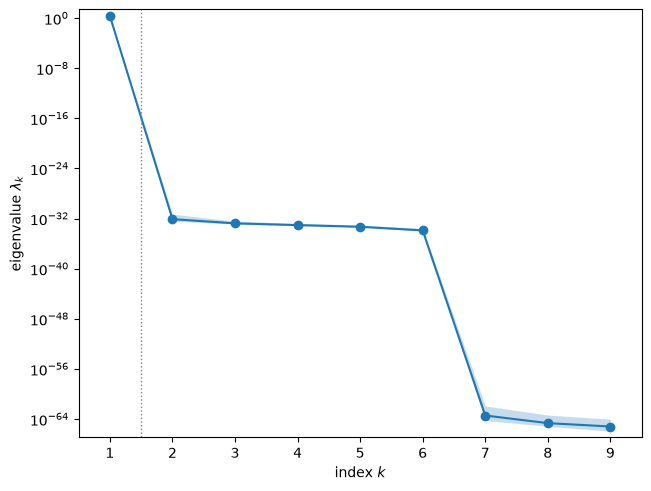

In [6]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
plt.close(fig)
fig

The first eigenvalue is $\lambda_1 = 2.213$, and $\lambda_2,\dots,\lambda_6$ are of order $10^{-33}$ and $\lambda_7,\lambda_8,\lambda_9$ of order $10^{-65}$: rounding errors of a rank-one matrix, as the formula above predicts. So $\lambda_1/\lambda_2$, about $10^{32}$, is the ratio of $\lambda_1$ to rounding error, not a measured gap. The estimate equals the sample second moment times $\|\boldsymbol\sigma\|^2$ (2.2129); the exact $\mathbb E[\Delta F_R^2]\,\|\boldsymbol\sigma\|^2$ is 2.3965, and the 8 % difference is Monte Carlo error in the second moment of a heavy-tailed lognormal output (sample variance 1.4944 against the exact 1.7090). The drop after $k = 6$ has a simple cause: three pairs of inputs have equal $\sigma_i$ ($Y$ and $L$, $\Psi_e$ and $T^2$, $f_\Psi$ and $(1-R_s)^2$), so their normalized gradient columns are identical bit for bit, and the three difference directions are exactly null even in floating point.

bootstrap mean subspace distance, k = 1..8: [2.48e-16 6.83e-01 6.64e-01 6.57e-01 2.01e-01 3.86e-15 3.57e-01 7.99e-01]


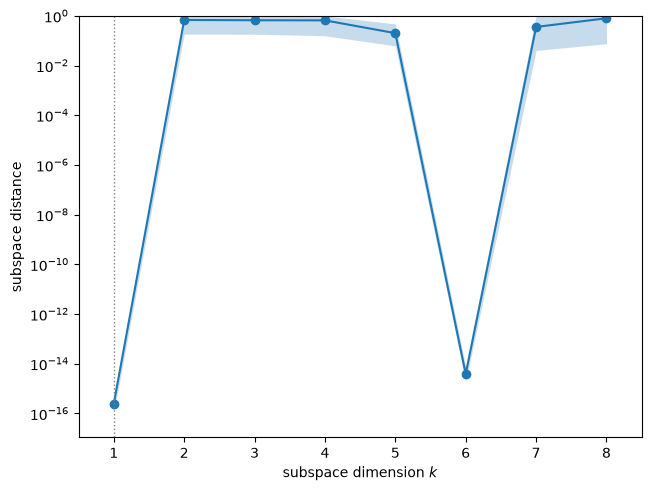

In [7]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..8:', np.array2string(sub.bootstrap_distances.mean(axis=0), precision=2))
fig

The bootstrap mean subspace distance for $k = 1$ is of order $10^{-16}$: every replicate returns $\mathbf w_1 = \boldsymbol\sigma/\|\boldsymbol\sigma\|$ up to rounding, because every gradient points along $\boldsymbol\sigma$. For $k = 2,\dots,5, 7, 8$ the distances are large (0.2–0.8), because those subspaces add eigenvectors of rounding error and are arbitrary. The distance at $k = 6$ (of order $10^{-15}$) is small for the tied-$\sigma$ reason above: that subspace is the complement of the three exactly null directions.

w1: Q 0.165, Y 0.478, L 0.478, Psi_e 0.397, beta 0.309, f_Psi 0.215, T2 0.397, one_minus_Ac 0.112, one_minus_Rs_sq 0.215
w1^2 = share of Var[ln(-dF_R)]: Q 0.027, Y 0.229, L 0.229, Psi_e 0.157, beta 0.096, f_Psi 0.046, T2 0.157, one_minus_Ac 0.013, one_minus_Rs_sq 0.046


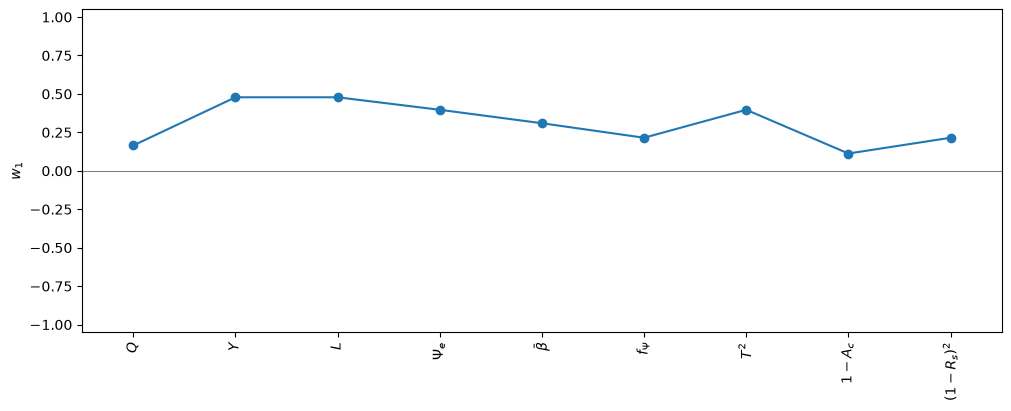

In [8]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0], labels=labels, figsize=(10, 4))
plt.close(fig)
share = sm.SIGMA**2 / np.sum(sm.SIGMA**2)
print('w1:', ', '.join(f'{n} {w:.3f}' for n, w in zip(sm.NAMES, w1)))
print('w1^2 = share of Var[ln(-dF_R)]:', ', '.join(f'{n} {s:.3f}' for n, s in zip(sm.NAMES, share)))
fig

All nine weights are positive, and $\mathbf w_1 = \boldsymbol\sigma/\|\boldsymbol\sigma\|$ to about $2\times10^{-16}$. Since $\ln(-\Delta F_R)$ is a sum of independent Gaussians $z_i$, $w_{1i}^2 = \sigma_i^2/\|\boldsymbol\sigma\|^2$ is also the share of $\mathrm{Var}[\ln(-\Delta F_R)]$ due to input $i$ (its first-order Sobol index). The sulfate yield $Y$ and lifetime $L$ carry 0.229 each, $\Psi_e$ and $T^2$ 0.157 each and $\bar\beta$ 0.096, while the source strength $Q$ (0.027) and the cloud-free fraction $1-A_c$ (0.013), the inputs with the smallest relative uncertainties, matter least.

active variable y = w1^T x: range [-3.44, 2.74]; dF_R = K exp(sum mu) exp(|sigma| y) with K exp(sum mu) = -0.8893 W/m^2, |sigma| = 0.8480
max |dF_R - K exp(sum mu + |sigma| y)| / |dF_R| = 1.6e-15


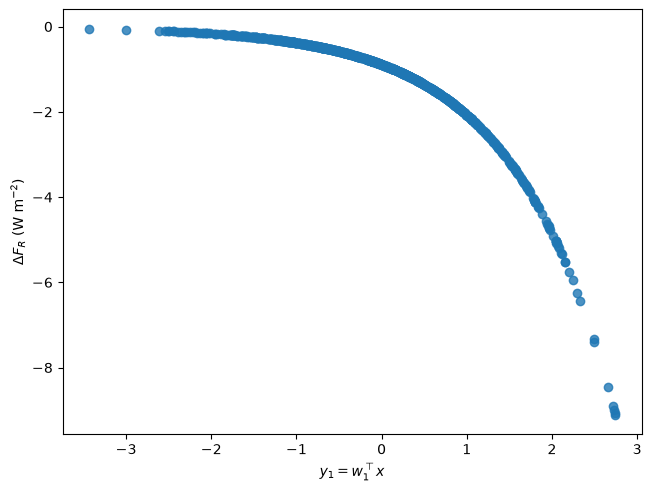

In [9]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=Z, f=f, dims=1, qoi_label=r'$\Delta F_R$ (W m$^{-2}$)')
plt.close(fig)
y = space.to_normalized(Z) @ w1
print(f'active variable y = w1^T x: range [{y.min():.2f}, {y.max():.2f}]; '
      f'dF_R = K exp(sum mu) exp(|sigma| y) with K exp(sum mu) = {sm.forcing(np.exp(sm.MU)):.4f} W/m^2, '
      f'|sigma| = {np.linalg.norm(sm.SIGMA):.4f}')
print(f'max |dF_R - K exp(sum mu + |sigma| y)| / |dF_R| = '
      f'{np.max(np.abs(sm.forcing(np.exp(sm.MU)) * np.exp(np.linalg.norm(sm.SIGMA) * y) - f) / np.abs(f)):.1e}')
fig

least-squares line: slope 0.848036 (|sigma| = 0.848036), intercept -0.117327 (ln(-K) + sum mu = -0.117327)


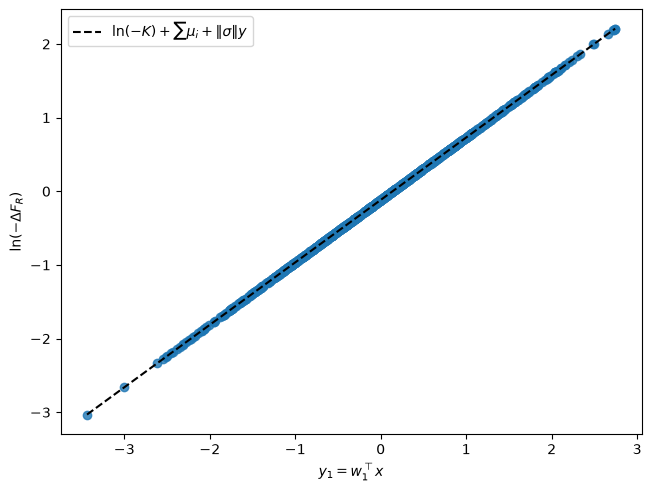

In [10]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=Z, f=np.log(-f), dims=1, qoi_label=r'$\ln(-\Delta F_R)$')
ys = np.linspace(y.min(), y.max(), 2)
ax.plot(ys, np.log(-sm.forcing(np.exp(sm.MU))) + np.linalg.norm(sm.SIGMA) * ys, 'k--',
        label=r'$\ln(-K) + \sum\mu_i + \|\sigma\| y$')
ax.legend()
plt.close(fig)
slope, icpt = np.polyfit(y, np.log(-f), 1)
print(f'least-squares line: slope {slope:.6f} (|sigma| = {np.linalg.norm(sm.SIGMA):.6f}), '
      f'intercept {icpt:.6f} (ln(-K) + sum mu = {np.log(-sm.forcing(np.exp(sm.MU))):.6f})')
fig

The active variable $y = \mathbf w_1^T\mathbf x$ ranges over $[-3.44, 2.74]$. $\Delta F_R$ is an exact function of $y$, $-0.8893\,e^{0.8480\,y}$ W m$^{-2}$ (largest relative deviation of order $10^{-15}$, rounding error), and $\ln(-\Delta F_R)$ lies on a line whose least-squares slope 0.848036 and intercept $-0.117327$ equal $\|\boldsymbol\sigma\|$ and $\ln(-K)+\sum_i\mu_i$. The eight inactive directions have no effect on $\Delta F_R$ at all: in log coordinates the model is a ridge function of one variable.

#### The same analysis in physical coordinates

To see what the log transform buys, we repeat the analysis with the gradient with respect to the physical inputs, $\partial\Delta F_R/\partial x_i = \Delta F_R/x_i$, normalized by each input's lognormal mean $m_i$ and standard deviation $s_i$, $x^{\mathrm{norm}}_i = (x_i - m_i)/s_i$. The library has no lognormal space, so we pass `ac.Gaussian(m, s**2)`, used here only for this affine normalization; the samples are the same lognormal ones. The normalized gradient is $\Delta F_R\, s_i/x_i$, which changes direction from sample to sample, so $\mathbf C$ is no longer rank one.

eigenvalues: [1.980e+00 7.852e-02 6.084e-02 4.852e-02 2.095e-02 5.909e-03 2.939e-03
 1.533e-03 3.431e-04]
n = 1; lambda_1/lambda_2 = 25.2, lambda_2/lambda_3 = 1.29; |w1(phys) . w1(log)| = 0.9997


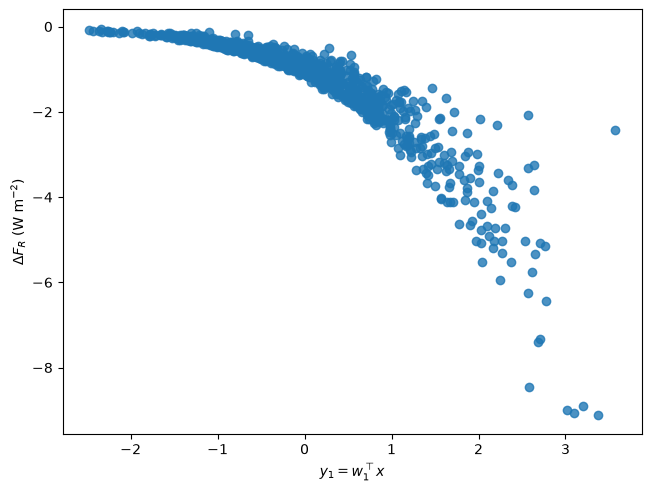

In [11]:
m_ln = np.exp(sm.MU + sm.SIGMA**2 / 2)                 # lognormal means
s_ln = m_ln * np.sqrt(np.expm1(sm.SIGMA**2))           # lognormal standard deviations
space_phys = ac.Gaussian(m_ln, s_ln**2, names=list(sm.NAMES))
sub_phys = ac.active_subspace(space=space_phys, X=X, f=f, grads=G / X, estimator='as',
                              nboot=500, rng=SEED)
lp = sub_phys.eigenvalues
print('eigenvalues:', np.array2string(lp, precision=3))
print(f'n = {sub_phys.n}; lambda_1/lambda_2 = {lp[0] / lp[1]:.1f}, lambda_2/lambda_3 = {lp[1] / lp[2]:.2f}; '
      f'|w1(phys) . w1(log)| = {abs(sub_phys.W[:, 0] @ w1):.4f}')
fig, ax = ac.plotting.plot_sufficient_summary(sub_phys, X=X, f=f, dims=1,
                                              qoi_label=r'$\Delta F_R$ (W m$^{-2}$)')
plt.close(fig)
fig

In physical coordinates the gap rule also picks $n = 1$, with $\lambda_1/\lambda_2 = 25.2$ ($\lambda_2/\lambda_3 = 1.29$), and the first eigenvector is nearly the one from log coordinates ($|\mathbf w_1^{\mathrm{phys}}\cdot\mathbf w_1^{\log}| = 0.9997$). But the summary plot spreads out as $y$ grows, because the normalized gradient $\Delta F_R\,s_i/x_i$ changes direction with $\mathbf x$: a product of inputs is not a ridge function of the inputs themselves. The log transform turns an approximate one-dimensional structure into an exact one.

#### Surrogates on the active variable

We fit polynomials in the single active variable and report the leave-one-out $R^2$: a cubic for $\Delta F_R$ and a line for $\ln(-\Delta F_R)$ in log coordinates, and a cubic for $\Delta F_R$ on the physical-coordinate active variable.

LOO R^2: cubic in y for dF_R (log coordinates) 0.9946; line in y for ln(-dF_R) 1.000000000000; cubic in y for dF_R (physical coordinates) 0.8713


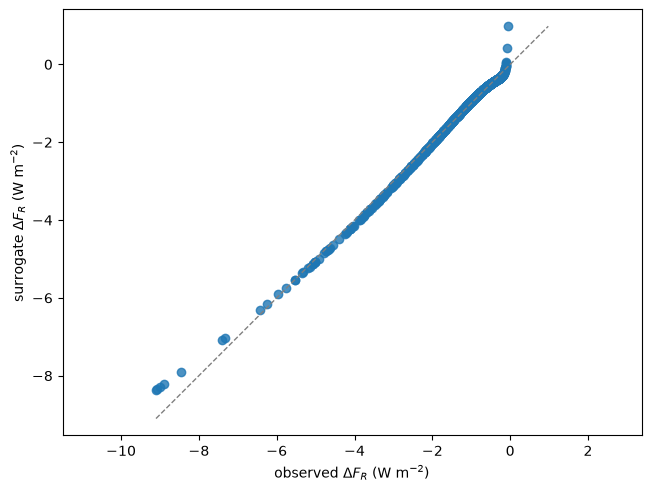

In [12]:
sur3 = ac.fit_surrogate(X=Z, f=f, subspace=sub, kind='poly', degree=3)
sur_log = ac.fit_surrogate(X=Z, f=np.log(-f), subspace=sub, kind='poly', degree=1)
sur_phys = ac.fit_surrogate(X=X, f=f, subspace=sub_phys, kind='poly', degree=3)
print(f'LOO R^2: cubic in y for dF_R (log coordinates) {sur3.loo_r_squared:.4f}; '
      f'line in y for ln(-dF_R) {sur_log.loo_r_squared:.12f}; '
      f'cubic in y for dF_R (physical coordinates) {sur_phys.loo_r_squared:.4f}')
fig, ax = ac.plotting.plot_surrogate_fit(sur3, X=Z, f=f, qoi_label=r'$\Delta F_R$ (W m$^{-2}$)')
plt.close(fig)
fig

The line in $y$ for $\ln(-\Delta F_R)$ has leave-one-out $R^2 = 1$ to twelve digits, as it must. The cubic in $y$ for $\Delta F_R$ in log coordinates has leave-one-out $R^2 = 0.9946$; its error (figure) is the cubic's approximation of the exponential at the ends of the range, not scatter about the ridge. The same cubic on the physical-coordinate active variable reaches only 0.8713.

### Comparison with the paper

Charlson et al. [[1]](https://doi.org/10.1126/science.255.5043.423) report a point estimate, not a sampling study or an active subspace; the benchmark's distributions and reference moments come from Penner et al. [[2]](https://doi.org/10.1175/1520-0477(1994)075<0375:QAMUOC>2.0.CO;2) and UQTestFuns [[3]](https://doi.org/10.21105/joss.05671). The cell computes the notebook's values.

In [13]:
xn = sm.NOMINAL_CHARLSON
Bn = sm.burden(xn, sm.AREA_CHARLSON)
rows = [
    ('B at Charlson nominals, g SO4/m^2 (Table 1)', '4.6e-3', f'{Bn:.2e}'),
    ('delta at Charlson nominals (Table 1)', '0.04', f'{xn[3] * xn[5] * Bn:.4f}'),
    ('dF_R at Charlson nominals, F_T = 1370, A = 5e14 (Table 1)', '-1.3', f'{sm.forcing(xn, sm.S0_CHARLSON, sm.AREA_CHARLSON):.3f}'),
    ('dF_R at the benchmark medians, S0 = 1361, A = 5.1e14', 'not reported', f'{sm.forcing(np.exp(sm.MU)):.3f}'),
    ('uncertainty factor (text p. 426) vs geometric std exp|sigma|', 'factor of 2', f'{np.exp(np.linalg.norm(sm.SIGMA)):.2f}'),
    ('mean of dF_R (UQTestFuns, analytic)', '-1.2741', f'{mean:.4f} exact, {f.mean():.4f} sample'),
    ('variance of dF_R (UQTestFuns, analytic)', '1.7089', f'{var:.4f} exact, {f.var(ddof=1):.4f} sample'),
    ('active subspace dimension, eigenvalues, w1', 'not reported', f'n = {sub.n}, lambda_1 = {lam[0]:.3f}'),
]
for q, p, v in rows:
    print(f'{q:62s} {p:>13s}   {v}')

B at Charlson nominals, g SO4/m^2 (Table 1)                           4.6e-3   4.32e-03
delta at Charlson nominals (Table 1)                                    0.04   0.0367
dF_R at Charlson nominals, F_T = 1370, A = 5e14 (Table 1)               -1.3   -1.218
dF_R at the benchmark medians, S0 = 1361, A = 5.1e14            not reported   -0.889
uncertainty factor (text p. 426) vs geometric std exp|sigma|     factor of 2   2.34
mean of dF_R (UQTestFuns, analytic)                                  -1.2741   -1.2741 exact, -1.2586 sample
variance of dF_R (UQTestFuns, analytic)                               1.7089   1.7090 exact, 1.4944 sample
active subspace dimension, eigenvalues, w1                      not reported   n = 1, lambda_1 = 2.213


| Quantity | Paper value | Notebook value |
|---|---|---|
| Sulfate burden $B$ at Charlson's nominal values (g SO$_4^{2-}$ m$^{-2}$) | $4.6\times10^{-3}$ [1, Table 1] | $4.32\times10^{-3}$ |
| Optical depth $\delta$ at the nominal values | 0.04 [1, Table 1] | 0.0367 |
| $\Delta F_R$ at the nominal values, $F_T = 1370$, $A = 5\times10^{14}$ (W m$^{-2}$) | $-1.3$ [1, Table 1] | $-1.218$ |
| $\Delta F_R$ at the benchmark medians, $S_0 = 1361$, $A = 5.1\times10^{14}$ (W m$^{-2}$) | not reported | $-0.889$ |
| Uncertainty of $\Delta F_R$ | "factor of 2" around $-1$ W m$^{-2}$ [1, p. 426] | geometric standard deviation $e^{\lVert\boldsymbol\sigma\rVert} = 2.34$ |
| Mean of $\Delta F_R$ (W m$^{-2}$) | $-1.2741$ [3], analytic | $-1.2741$ exact, $-1.2586$ sample |
| Variance of $\Delta F_R$ ((W m$^{-2}$)$^2$) | 1.7089 [3], analytic | 1.7090 exact, 1.4944 sample |
| Active subspace | not reported | $n = 1$, $\lambda_1 = 2.213$, $\mathbf w_1 = \boldsymbol\sigma/\lVert\boldsymbol\sigma\rVert$ |

Charlson's Table 1 burden is not reproduced by the table's own inputs: $3\,Q\,Y\,\tau/A$ with $Q = 90$ Tg S yr$^{-1}$, $Y = 0.4$, $\tau = 0.02$ yr and $A = 5\times10^{14}$ m$^2$ gives $4.32\times10^{-3}$ g m$^{-2}$ ($4.5\times10^{-5}$ mol m$^{-2}$, against the table's $4.8\times10^{-5}$). Carried through, it gives $\delta = 0.0367$ and $\Delta F_R = -1.218$ W m$^{-2}$, against the table's rounded $0.04$ and $-1.3$; we do not know how the table's burden was computed. The text (p. 426) puts the forcing at $-1$ W m$^{-2}$, uncertain to a factor of 2; under the benchmark distributions the median is $-0.889$ W m$^{-2}$ and the geometric standard deviation 2.34. The exact mean and variance agree with UQTestFuns (the exact variance, 1.70897, rounds to 1.7090; UQTestFuns prints 1.7089). The sample variance from 1000 samples is 13 % below the exact one, which is ordinary for a lognormal output with $\|\boldsymbol\sigma\| = 0.85$.

### References

[1] R. J. Charlson, S. E. Schwartz, J. M. Hales, R. D. Cess, J. A. Coakley, Jr., J. E. Hansen, and D. J. Hofmann. [Climate forcing by anthropogenic aerosols](https://doi.org/10.1126/science.255.5043.423). *Science*, 255(5043):423–430, 1992.

[2] J. E. Penner et al. [Quantifying and minimizing uncertainty of climate forcing by anthropogenic aerosols](https://doi.org/10.1175/1520-0477(1994)075<0375:QAMUOC>2.0.CO;2). *Bulletin of the American Meteorological Society*, 75(3):375–400, 1994.

[3] D. Wicaksono and M. Hecht. UQTestFuns: A Python3 library of uncertainty quantification (UQ) test functions. *Journal of Open Source Software*, 8(90):5671, 2023. https://doi.org/10.21105/joss.05671. Sulfur model page: <https://uqtestfuns.readthedocs.io/en/latest/test-functions/sulfur.html>.

[4] M. A. Tatang, W. Pan, R. G. Prinn, and G. J. McRae. [An efficient method for parametric uncertainty analysis of numerical geophysical models](https://doi.org/10.1029/97JD01654). *Journal of Geophysical Research: Atmospheres*, 102(D18):21925–21932, 1997.

[5] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[R1]: https://doi.org/10.1126/science.255.5043.423
[R2]: https://doi.org/10.1175/1520-0477(1994)075<0375:QAMUOC>2.0.CO;2
[R3]: https://doi.org/10.21105/joss.05671
[R4]: https://doi.org/10.1029/97JD01654

### Acknowledgments

From [[1]][R1], note 73: "This work has been supported by Department of Energy (DOE) grant DE-FG02-85ER60314 (R.D.C.), NSF grant ATM-8813825 and DOE Atmospheric Radiation Measurement Program (R.J.C.), NSF grant ATM-8912669 (J.A.C.), DOE contract DE-AC06-76RLO 1830 (J.M.H.), National Aeronautics and Space Administration Climate Program and Environmental Protection Agency Global Change and Climate Change Divisions and grant R816395 (J.E.H.), the National Oceanic and Atmospheric Administration (D.J.H.), and DOE contract DE-AC02-76CH00016 (S.E.S.)."

In [14]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 2.8 s
